# Runge-Kutta solution of a forced ODE

The fourth-order update is compared with the analytical solution.

![](media/coursework-8cb2b4207811-8cb2b420.png)
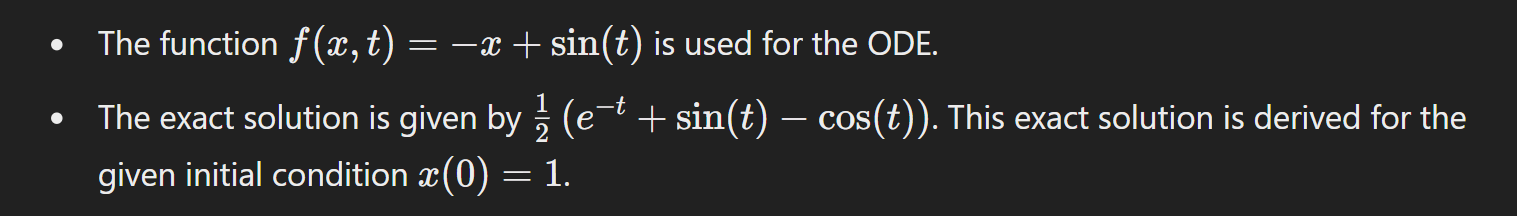

$$\frac{dx}{dt}=-x+\sin t,\quad x(0)=1,\qquad x(t)=\frac32e^{-t}+\frac12(\sin t-\cos t).$$

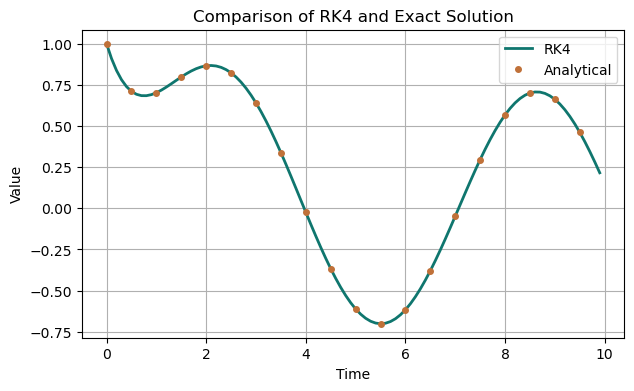

Maximum absolute error: 5.03e-07


In [1]:
import numpy as np
import matplotlib.pyplot as plt

def rk4_step(x, t, dt):
    
    f1 = f(x, t)
    f2 = f(x + 0.5 * dt * f1, t + 0.5 * dt)
    f3 = f(x + 0.5 * dt * f2, t + 0.5 * dt)
    f4 = f(x + dt * f3, t + dt)
    
    return x + (dt / 6) * (f1 + 2 * f2 + 2 * f3 + f4)

#dx/dt = -x + sin(t)
def f(x, t):
    return -x + np.sin(t)

x0 = 1.0
t0 = 0.0
tf = 10.0
dt = 0.1

t_points = np.arange(t0, tf, dt)

x_points = np.zeros_like(t_points)
x_points[0] = x0

for i in range(1, len(t_points)):
    x_points[i] = rk4_step( x_points[i-1], t_points[i-1], dt)

def exact_solution(t):
    return 1.5*np.exp(-t) + 0.5*(np.sin(t) - np.cos(t))

exact_points = exact_solution(t_points)

plt.figure(figsize=(7, 4))
plt.plot(t_points, x_points, color='#0f766e', linewidth=2, label='RK4')
plt.plot(t_points[::5], exact_points[::5], 'o', color='#c07139', markersize=4, label='Analytical')

plt.xlabel('Time')
plt.ylabel('Value')
plt.title('Comparison of RK4 and Exact Solution')
plt.legend()
plt.grid(True)
plt.show()

assert exact_solution(0) == x0
assert np.max(np.abs(x_points-exact_points)) < 2e-6
print(f"Maximum absolute error: {np.max(np.abs(x_points-exact_points)):.2e}")